In [1]:
import pandas as pd
import requests
import time

print("Testing connection to Apache Jira...")
test_url = "https://issues.apache.org/jira/rest/api/2/search?jql=project=SPARK&maxResults=1"
res = requests.get(test_url)

if res.status_code == 200:
    print("Connection successful! Ready to pull data.")
else:
    print(f"Connection failed with status: {res.status_code}")

Testing connection to Apache Jira...
Connection successful! Ready to pull data.


In [3]:
project_key = "SPARK"
base_url = "https://issues.apache.org/jira/rest/api/2/search"
total_tickets_to_fetch = 1000  # Pulls 1,000 tickets with all their historical transitions
batch_size = 100

events = []
start_at = 0

print(f"Downloading real event logs for {project_key}...")

while start_at < total_tickets_to_fetch:
    params = {
        "jql": f"project = {project_key} ORDER BY created DESC",
        "startAt": start_at,
        "maxResults": batch_size,
        "expand": "changelog",
        "fields": "key,created,priority,status,components,issuetype"
    }
    
    response = requests.get(base_url, params=params)
    data = response.json()
    issues = data.get("issues", [])
    
    if not issues:
        break
        
    for issue in issues:
        ticket_id = issue["key"]
        created_at = issue["fields"]["created"]
        priority = issue["fields"]["priority"]["name"] if issue["fields"].get("priority") else "None"
        issue_type = issue["fields"]["issuetype"]["name"] if issue["fields"].get("issuetype") else "Unknown"
        
        # 1. Ticket Creation Event
        components = [c["name"] for c in issue["fields"].get("components", [])]
        initial_comp = components[0] if components else "General/Triage"
        
        events.append({
            "ticket_id": ticket_id,
            "event_time": created_at,
            "event_type": "Created",
            "field": "Component",
            "from_value": None,
            "to_value": initial_comp,
            "priority": priority,
            "issue_type": issue_type
        })
        
        # 2. Historical Audit Log (Reassignments & Status Changes)
        histories = issue.get("changelog", {}).get("histories", [])
        for history in histories:
            change_time = history["created"]
            for item in history.get("items", []):
                field_name = item.get("field")
                if field_name in ["Component", "status", "priority"]:
                    events.append({
                        "ticket_id": ticket_id,
                        "event_time": change_time,
                        "event_type": "Change",
                        "field": field_name,
                        "from_value": item.get("fromString"),
                        "to_value": item.get("toString"),
                        "priority": priority,
                        "issue_type": issue_type
                    })
                    
    start_at += batch_size
    print(f"Fetched {start_at} / {total_tickets_to_fetch} tickets...")
    time.sleep(0.2)

# Convert to DataFrame
df_raw = pd.DataFrame(events)
print(f"\nDownload finished! Total rows: {len(df_raw)}")
df_raw.head()

Fetched 100 / 1000 tickets...
Fetched 200 / 1000 tickets...
Fetched 300 / 1000 tickets...
Fetched 400 / 1000 tickets...
Fetched 500 / 1000 tickets...
Fetched 600 / 1000 tickets...
Fetched 700 / 1000 tickets...
Fetched 800 / 1000 tickets...
Fetched 900 / 1000 tickets...
Fetched 1000 / 1000 tickets...

Download finished! Total rows: 1829


,ticket_id,event_time,event_type,field,from_value,to_value,priority,issue_type
0,SPARK-59996,2026-10-06T07:52:57.000+0000,Created,Component,None,PySpark,Major,Task
1,SPARK-59995,2026-10-06T06:44:59.000+0000,Created,Component,None,SQL,Major,Bug
2,SPARK-59994,2026-10-06T06:38:23.000+0000,Created,Component,None,SQL,Major,Improvement
3,SPARK-59993,2026-10-05T23:27:00.000+0000,Created,Component,None,PySpark,Major,Sub-task
4,SPARK-59992,2026-10-05T23:24:33.000+0000,Created,Component,None,SQL,Major,Bug


In [5]:
# 1. Clean timestamps to standard datetime format
df_raw['event_time'] = pd.to_datetime(df_raw['event_time'])

# 2. Extract total hops (how many times a ticket was reassigned to a new component)
component_changes = df_raw[df_raw['field'] == 'Component']
hops = component_changes.groupby('ticket_id').size() - 1
hops = hops.apply(lambda x: max(x, 0)).reset_index(name='total_hops')

# 3. Calculate lifecycle times (created, closed, and duration)
ticket_info = df_raw.groupby('ticket_id').agg(
    created_at=('event_time', 'min'),
    last_update=('event_time', 'max'),
    priority=('priority', 'first'),
    issue_type=('issue_type', 'first'),
    initial_component=('to_value', 'first')
).reset_index()

# 4. Check if ticket has a resolved/closed status change
resolved_events = df_raw[
    (df_raw['field'] == 'status') & 
    (df_raw['to_value'].isin(['Resolved', 'Closed']))
]
closed_times = resolved_events.groupby('ticket_id')['event_time'].min().reset_index(name='resolved_at')

# 5. Merge into one clean analysis table
df_tickets = ticket_info.merge(hops, on='ticket_id', how='left')
df_tickets = df_tickets.merge(closed_times, on='ticket_id', how='left')
df_tickets['total_hops'] = df_tickets['total_hops'].fillna(0).astype(int)

# For resolved tickets, calculate resolution time in hours
df_resolved = df_tickets[df_tickets['resolved_at'].notnull()].copy()
df_resolved['resolution_hours'] = (
    (df_resolved['resolved_at'] - df_resolved['created_at']).dt.total_seconds() / 3600.0
).round(2)

print(f"Total unique tickets: {len(df_tickets)}")
print(f"Total resolved tickets available for MTTR analysis: {len(df_resolved)}")
df_resolved[['ticket_id', 'priority', 'issue_type', 'initial_component', 'total_hops', 'resolution_hours']].head()

Total unique tickets: 1000
Total resolved tickets available for MTTR analysis: 671


,ticket_id,priority,issue_type,initial_component,total_hops,resolution_hours
0,SPARK-58996,Major,Bug,SQL,0,307.49
1,SPARK-58997,Major,Improvement,Project Infra,0,0.01
3,SPARK-58999,Major,Improvement,Spark Core,0,311.16
5,SPARK-59001,Major,Sub-task,SQL,2,34.39
6,SPARK-59002,Major,Sub-task,Kubernetes,0,0.41


In [7]:
# 1. Bucket tickets by number of hops
def assign_hop_tier(hops):
    if hops == 0:
        return '0 Hops (Direct Fix)'
    elif hops == 1:
        return '1 Hop'
    elif hops == 2:
        return '2 Hops'
    else:
        return '3+ Hops (Chronic Bounce)'

df_resolved['hop_tier'] = df_resolved['total_hops'].apply(assign_hop_tier)

# 2. Compute volume, average, median, and 90th percentile MTTR
hop_metrics = df_resolved.groupby('hop_tier')['resolution_hours'].agg(
    ticket_count='count',
    avg_hours='mean',
    median_hours='median',
    p90_hours=lambda x: x.quantile(0.90)
).round(2).reset_index()

# 3. Calculate the percentage of total ticket volume in each bucket
hop_metrics['pct_of_total_volume'] = (
    (hop_metrics['ticket_count'] / len(df_resolved)) * 100
).round(1)

# Sort logically by hop depth
sorter = ['0 Hops (Direct Fix)', '1 Hop', '2 Hops', '3+ Hops (Chronic Bounce)']
hop_metrics['sort_key'] = hop_metrics['hop_tier'].map(lambda x: sorter.index(x) if x in sorter else 99)
hop_metrics = hop_metrics.sort_values('sort_key').drop(columns=['sort_key'])

print("=== RESOLUTION TIME BY REASSIGNMENT (HOPS) ===")
hop_metrics

=== RESOLUTION TIME BY REASSIGNMENT (HOPS) ===


,hop_tier,ticket_count,avg_hours,median_hours,p90_hours,pct_of_total_volume
0,0 Hops (Direct Fix),605,67.00,12.82,201.66,90.2
1,1 Hop,41,72.98,22.82,198.54,6.1
2,2 Hops,22,118.05,46.02,329.48,3.3
3,3+ Hops (Chronic Bounce),3,95.10,99.67,154.22,0.4


In [9]:
# 1. Identify which components produce the highest bounce rates
component_stats = df_resolved.groupby('initial_component').agg(
    total_tickets=('ticket_id', 'count'),
    bounced_tickets=('total_hops', lambda x: (x > 0).sum()),
    avg_resolution_hours=('resolution_hours', 'mean'),
    median_resolution_hours=('resolution_hours', 'median')
).reset_index()

# Filter for components with meaningful volume (at least 15 tickets)
component_stats = component_stats[component_stats['total_tickets'] >= 15].copy()
component_stats['bounce_rate_pct'] = (
    (component_stats['bounced_tickets'] / component_stats['total_tickets']) * 100
).round(1)

# Sort by bounce rate descending
component_stats = component_stats.sort_values(by='bounce_rate_pct', ascending=False)

# 2. Check bounce rate across Issue Types (Bug vs. Improvement vs. Task)
issue_type_stats = df_resolved.groupby('issue_type').agg(
    total_tickets=('ticket_id', 'count'),
    bounced_tickets=('total_hops', lambda x: (x > 0).sum()),
    median_hours=('resolution_hours', 'median')
).reset_index()

issue_type_stats['bounce_rate_pct'] = (
    (issue_type_stats['bounced_tickets'] / issue_type_stats['total_tickets']) * 100
).round(1)
issue_type_stats = issue_type_stats.sort_values(by='bounce_rate_pct', ascending=False)

print("=== TOP COMPONENTS BY BOUNCE RATE (Min 15 tickets) ===")
display(component_stats.head(10))

print("\n=== BOUNCE RATE BY ISSUE TYPE ===")
display(issue_type_stats)

=== TOP COMPONENTS BY BOUNCE RATE (Min 15 tickets) ===


,initial_component,total_tickets,bounced_tickets,avg_resolution_hours,median_resolution_hours,bounce_rate_pct
12,PySpark,38,13,103.495000,32.675,34.2
13,SQL,173,27,125.023699,86.930,15.6
6,ML,26,4,33.360000,19.090,15.4
10,Project Infra,22,2,39.745000,2.460,9.1
0,Build,28,2,81.812143,13.185,7.1
14,Spark Core,49,2,131.668571,66.050,4.1
1,Connect,137,4,23.337226,1.300,2.9
5,Kubernetes,148,4,10.215473,3.300,2.7



=== BOUNCE RATE BY ISSUE TYPE ===


,issue_type,total_tickets,bounced_tickets,median_hours,bounce_rate_pct
7,Test,17,10,18.100,58.8
1,Dependency upgrade,2,1,15.245,50.0
6,Task,5,2,254.720,40.0
2,Documentation,6,1,139.695,16.7
0,Bug,85,10,56.750,11.8
3,Improvement,129,15,74.700,11.6
5,Sub-task,423,27,6.570,6.4
4,New Feature,3,0,6.010,0.0
8,Umbrella,1,0,212.650,0.0


C:\Users\Tanuja\AppData\Local\Temp\ipykernel_21144\3244386500.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Tanuja\AppData\Local\Temp\ipykernel_21144\3244386500.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


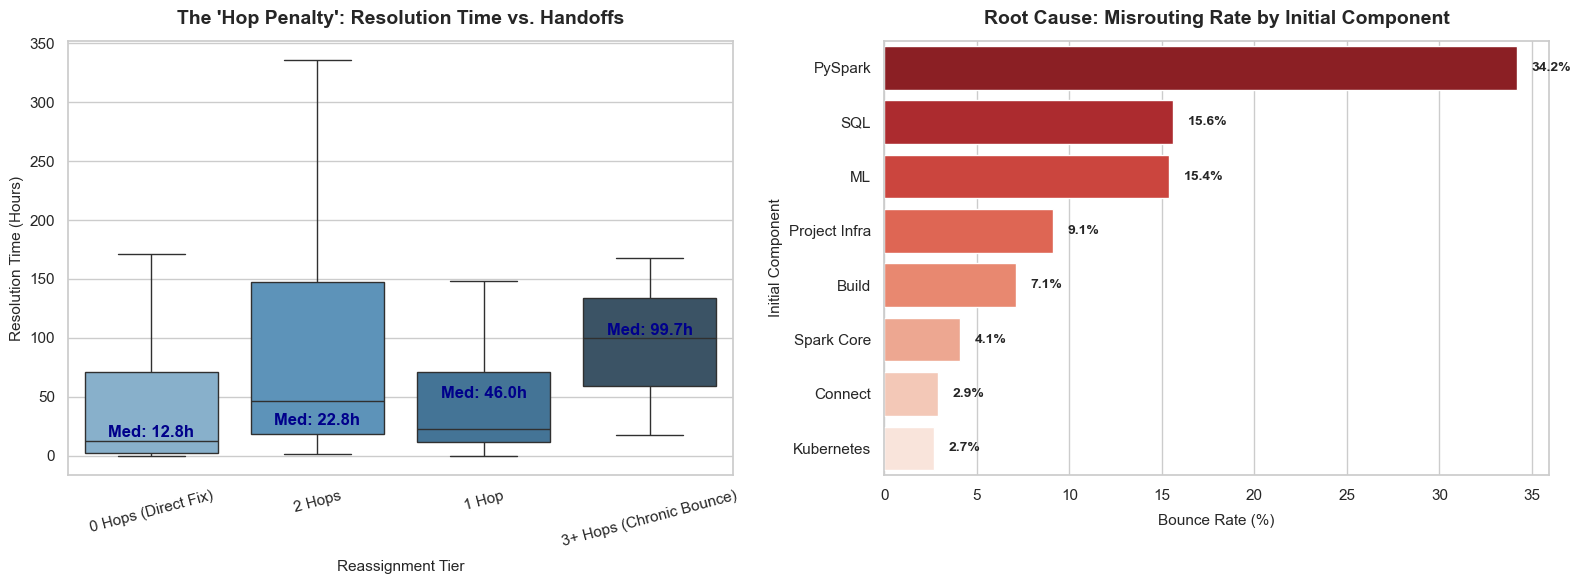

Charts successfully generated and saved as 'ticket_bottleneck_analysis.png'!


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Hop Penalty (Median & Distribution)
sns.boxplot(
    ax=axes[0],
    data=df_resolved[df_resolved['total_hops'] <= 3],
    x='hop_tier',
    y='resolution_hours',
    showfliers=False,  # Hides extreme outliers for clean visual scaling
    palette='Blues_d'
)
axes[0].set_title("The 'Hop Penalty': Resolution Time vs. Handoffs", fontsize=14, weight='bold', pad=12)
axes[0].set_xlabel("Reassignment Tier", fontsize=11, labelpad=8)
axes[0].set_ylabel("Resolution Time (Hours)", fontsize=11)
axes[0].tick_params(axis='x', rotation=15)

# Annotate median values on Chart 1
medians = df_resolved.groupby('hop_tier')['resolution_hours'].median()
for i, tier in enumerate(['0 Hops (Direct Fix)', '1 Hop', '2 Hops', '3+ Hops (Chronic Bounce)']):
    med_val = medians.get(tier, 0)
    axes[0].text(i, med_val + 3, f"Med: {med_val:.1f}h", horizontalalignment='center', weight='semibold', color='darkblue')

# Chart 2: Root Cause - Top Components by Bounce Rate
sns.barplot(
    ax=axes[1],
    data=component_stats.head(8),
    x='bounce_rate_pct',
    y='initial_component',
    palette='Reds_r'
)
axes[1].set_title("Root Cause: Misrouting Rate by Initial Component", fontsize=14, weight='bold', pad=12)
axes[1].set_xlabel("Bounce Rate (%)", fontsize=11, labelpad=8)
axes[1].set_ylabel("Initial Component", fontsize=11)

# Annotate exact percentages on Chart 2
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(f"{width:.1f}%", 
                     (width + 0.8, p.get_y() + p.get_height() / 2),
                     va='center', fontsize=10, weight='semibold')

plt.tight_layout()
plt.savefig("ticket_bottleneck_analysis.png", dpi=300)
plt.show()

print("Charts successfully generated and saved as 'ticket_bottleneck_analysis.png'!")

In [13]:
# Calculate high-impact summary statistics for the executive brief
total_analyzed = len(df_resolved)
bounced_total = len(df_resolved[df_resolved['total_hops'] > 0])
bounce_share_pct = round((bounced_total / total_analyzed) * 100, 1)

direct_median = df_resolved[df_resolved['total_hops'] == 0]['resolution_hours'].median()
bounced_median = df_resolved[df_resolved['total_hops'] > 0]['resolution_hours'].median()
hop_multiplier = round(bounced_median / direct_median, 1)

print("=" * 70)
print("EXECUTIVE DIAGNOSTIC SUMMARY: SERVICE DESK BOTTLENECK ANALYSIS")
print("=" * 70)
print(f"1. TOTAL RESOLVED TICKETS ANALYZED : {total_analyzed}")
print(f"2. OVERALL REASSIGNMENT (BOUNCE) RATE: {bounce_share_pct}% ({bounced_total} tickets)")
print(f"3. DIRECT RESOLUTION MEDIAN MTTR      : {direct_median:.1f} hours")
print(f"4. BOUNCED TICKET MEDIAN MTTR         : {bounced_median:.1f} hours")
print(f"5. RESOLUTION LATENCY MULTIPLIER      : {hop_multiplier}x slower when bounced")
print("=" * 70)

EXECUTIVE DIAGNOSTIC SUMMARY: SERVICE DESK BOTTLENECK ANALYSIS
1. TOTAL RESOLVED TICKETS ANALYZED : 671
2. OVERALL REASSIGNMENT (BOUNCE) RATE: 9.8% (66 tickets)
3. DIRECT RESOLUTION MEDIAN MTTR      : 12.8 hours
4. BOUNCED TICKET MEDIAN MTTR         : 28.7 hours
5. RESOLUTION LATENCY MULTIPLIER      : 2.2x slower when bounced


In [15]:
import os

print("Current folder where your files actually are:")
print(os.getcwd())


Current folder where your files actually are:
C:\Users\Tanuja


In [ ]:
import os
import shutil

source_folder = r"C:\Users\Tanuja"

# 1. Search for your it_ticket_bottleneck_analysis folder
target_folder = None
for root, dirs, files in os.walk(source_folder):
    if "it_ticket_bottleneck_analysis" in dirs:
        target_folder = os.path.join(root, "it_ticket_bottleneck_analysis")
        break

if not target_folder:
    # If not found automatically, default to desktop or create it
    target_folder = os.path.join(source_folder, "it_ticket_bottleneck_analysis")
    os.makedirs(target_folder, exist_ok=True)

print("Target folder located at:", target_folder)

# 2. Copy the notebook and the chart into the target folder
files_to_move = ["ticket_bottleneck_analysis.ipynb", "ticket_bottleneck_analysis.png"]

for file_name in files_to_move:
    src_file = os.path.join(source_folder, file_name)
    dst_file = os.path.join(target_folder, file_name)
    if os.path.exists(src_file):
        shutil.copy2(src_file, dst_file)
        print(f"Copied {file_name} into {target_folder}")
    else:
        print(f"Could not locate {file_name} in {source_folder}")

print("\nFinished! Check inside your it_ticket_bottleneck_analysis folder.")